# Pelatihan Model S-CLIPS v2.7 — Klasifikasi Subjek Jurnal SINTA

Notebook ini memperlihatkan **bagaimana model ML S-CLIPS v2.7 dilatih, diuji, dan disimpan**, langkah demi langkah.

**Masalah yang diselesaikan.** Pada v2.6, 1.102 jurnal mendapat label subjek *Unknown* karena judulnya tidak mengandung kata yang dikenali model (contoh: *Tanzhimuna*, *Farmanesia*, *Verstek*). Tujuan v2.7: **semua jurnal terklasifikasi, label yang ditampilkan memiliki keyakinan minimal 70%, dan jurnal baru dapat langsung diklasifikasikan tanpa melatih ulang model.**

**Alur keseluruhan**

```
CSV ekspor SINTA (16.768 jurnal aktif)
 └─ Tahap 1 (v2.6): pembersihan nama penerbit, aturan tipe penerbit,
                    model tipe penerbit & model Scopus-27
                    -> journals_classified_v2.6.xlsx + sclips_models_v2.6.pkl
     └─ Tahap 2 (v2.7, NOTEBOOK INI): model subjek SINTA diperkuat
                    -> sclips_models_v2.7.pkl  (dipakai layanan web)
```

| Bagian | Isi |
|---|---|
| 1 | Persiapan lingkungan |
| 2 | Data latih |
| 3 | Rekayasa fitur: kamus akar kata & petunjuk penerbit |
| 4 | Model & pelatihan berbobot multi-subjek |
| 5 | Kalibrasi keyakinan & aturan label ≥ 70% |
| 6 | Evaluasi 1 — data uji per judul, termasuk 6b: perbandingan SVM vs Naive Bayes vs Random Forest |
| 7 | Evaluasi 2 — data uji penerbit baru (simulasi jurnal baru) |
| 8 | Pelatihan model final & penyimpanan |
| 9 | Uji model final seperti di web |
| 10 | Kesimpulan |

> Cara menjalankan di Colab: upload `sclips_v2.7_sidang_colab.zip` ke panel **Files**, lalu **Runtime → Run all**. Sel pertama memasang versi library lalu me-restart runtime satu kali; setelah restart, klik **Run all** lagi. Waktu jalan keseluruhan sekitar 15–25 menit di Colab.

## 1. Persiapan lingkungan
Versi library dikunci sama dengan yang dipakai server web, karena file model `.pkl` hanya dijamin terbaca oleh versi yang sama.

In [1]:
import sys, os
IN_COLAB = 'google.colab' in sys.modules
import sklearn, numpy, scipy
NEED = {'scikit-learn': '1.6.1', 'numpy': '2.4.6', 'scipy': '1.16.3'}
HAVE = {'scikit-learn': sklearn.__version__, 'numpy': numpy.__version__, 'scipy': scipy.__version__}
if HAVE != NEED and IN_COLAB:
    print('Memasang versi library yang dikunci:', NEED)
    !pip install -q scikit-learn==1.6.1 numpy==2.4.6 scipy==1.16.3 openpyxl
    print('Selesai. Runtime akan restart sekarang. Setelah itu klik Runtime -> Run all sekali lagi.')
    os.kill(os.getpid(), 9)
print('Versi library:', HAVE, '-> OK' if HAVE == NEED else '-> BERBEDA, hasil bisa sedikit berbeda')

Versi library: {'scikit-learn': '1.6.1', 'numpy': '2.4.6', 'scipy': '1.16.3'} -> OK


In [2]:
import zipfile, glob
DIR = 'sclips_train'
if not os.path.isdir(DIR):
    zips = glob.glob('sclips_v2.7_sidang_colab*.zip') + glob.glob('/content/drive/MyDrive/**/sclips_v2.7_sidang_colab*.zip', recursive=True)
    if not zips:
        raise FileNotFoundError('Upload dulu sclips_v2.7_sidang_colab.zip ke panel Files (atau ke Google Drive).')
    zipfile.ZipFile(zips[0]).extractall(DIR)
WAJIB = ['journals_classified_v2.6.xlsx', 'sclips_models_v2.6.pkl', 'sclips_ml_service.py']
for f in WAJIB:
    assert os.path.exists(os.path.join(DIR, f)), f'File {f} tidak ditemukan di {DIR}'
print('File siap:', sorted(os.listdir(DIR)))

File siap: ['__pycache__', 'journals_classified_v2.6.xlsx', 'requirements.txt', 'sclips_ml_service.py', 'sclips_models_v2.6.pkl', 'sclips_models_v2.7.pkl']


In [3]:
import io, json, time, pickle, hashlib, collections, importlib.util, inspect, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 80); pd.set_option('display.width', 200)

# Kode layanan web (sclips_ml_service.py) dimuat di sini supaya pembentukan fitur saat PELATIHAN
# identik dengan saat PREDIKSI di web.
os.environ['SCLIPS_TASK_DB_PATH'] = os.path.join(DIR, 'tasks_notebook.db')
spec = importlib.util.spec_from_file_location('sclips_ml_service', os.path.join(DIR, 'sclips_ml_service.py'))
svc = importlib.util.module_from_spec(spec); sys.modules['sclips_ml_service'] = svc; spec.loader.exec_module(svc)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import MaxAbsScaler, Normalizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, GroupShuffleSplit

SINTA10 = svc.SINTA_10_SUBJECTS
RUMPUN = svc.SINTA_TO_SCOPUS_MAP           # subjek SINTA -> rumpun Scopus (4)
RN = sorted(set(RUMPUN.values()))
MD_MIN = svc.MULTIDISCIPLINARY_MIN_SINTA_SUBJECTS
T0 = time.time()
print('10 subjek SINTA :', SINTA10)
print('Rumpun Scopus   :', RN)

10 subjek SINTA : ['Agriculture', 'Art', 'Economy', 'Education', 'Engineering', 'Health', 'Humanities', 'Religion', 'Science', 'Social']
Rumpun Scopus   : ['Health Sciences', 'Life Sciences', 'Physical Sciences', 'Social Sciences']


## 2. Data latih
Sumber: ekspor SINTA `journals_export_20261105_161058_1.csv` (16.768 jurnal aktif) yang sudah dibersihkan pada tahap v2.6 dan tersimpan di sheet `2_Full_16768_Jurnal`.
Kolom yang dipakai model subjek hanya: **judul jurnal**, **nama penerbit**, dan **subjek SINTA asli** (sebagai label/jawaban benar).

In [4]:
df = pd.read_excel(os.path.join(DIR, 'journals_classified_v2.6.xlsx'), sheet_name='2_Full_16768_Jurnal')
df['pub'] = df.publisher_name_clean.fillna(df.publisher_name_raw).fillna('').astype(str)
df.loc[df.pub.str.strip().isin(['-', 'nan']), 'pub'] = ''
df['pkey'] = df.pub.map(svc.publisher_key)                        # kunci penerbit yang dinormalkan
df['title'] = df.journal_title.astype(str)
df['parts'] = df.subject_sinta_asli.map(svc.parse_sinta_subjects)  # "Education, Social" -> ['Education', 'Social']
df['tkey'] = df.title.str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
lab = df[df.parts.str.len() > 0].copy()                            # jurnal yang punya subjek SINTA = data berlabel

print(f'Jurnal aktif               : {len(df):,}')
print(f'Punya subjek SINTA (label) : {len(lab):,}')
print(f'Tanpa subjek SINTA         : {len(df) - len(lab):,}  <- inilah yang harus diprediksi model')
print(f'Unknown pada v2.6          : {int(df.is_ood.sum()):,}')
df[['journal_title', 'pub', 'subject_sinta_asli']].sample(8, random_state=1)

Jurnal aktif               : 16,768
Punya subjek SINTA (label) : 14,983
Tanpa subjek SINTA         : 1,785  <- inilah yang harus diprediksi model
Unknown pada v2.6          : 1,102


,journal_title,pub,subject_sinta_asli
15712,Media Gizi Ilmiah Indonesia,Kabar Gizi Indonesia,Health
14773,JSEF: Journal of Sharia Economics and Finance,Universitas Wiralodra,Economy
10972,Administrative and Environmental Law Review,Universitas Lampung,Social
15318,Horizon: Indonesian Journal of Multidisciplinary,Lembaga Intelektual Muda Maluku,"Economy, Humanities, Science, Education, Agriculture, Social"
1858,International Journal of Marine Engineering Innovation and Research,Institut Teknologi Sepuluh Nopember Surabaya,"Social, Science, Engineering"
825,Humanitas: Indonesian Psychological Journal,Universitas Ahmad Dahlan,"Humanities, Art"
9684,"Baselang: Jurnal Ilmu Pertanian, Peternakan, Perikanan dan Lingkungan",Universitas Muara Bungo,NaN
13221,Student Journal of Community Education,Universitas Negeri Gorontalo,"Education, Social"


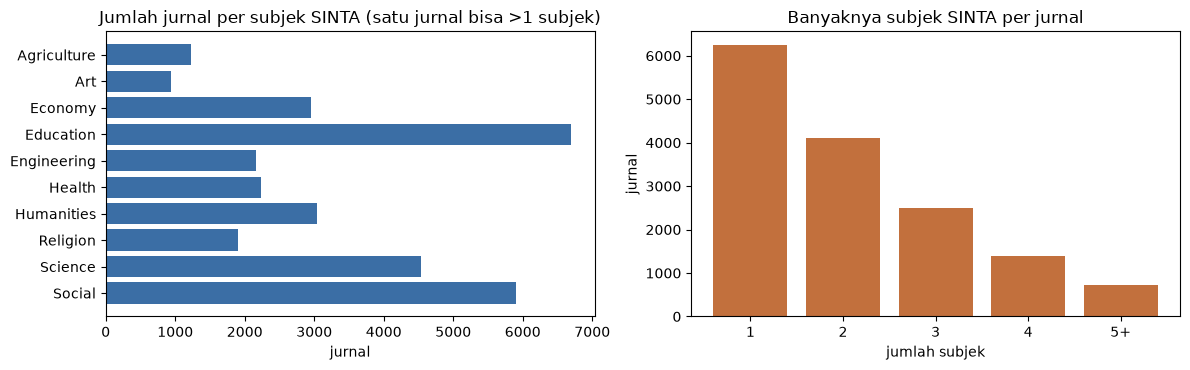

58.3% jurnal punya lebih dari satu subjek SINTA; 2,135 jurnal punya >= 4 subjek (ditampilkan "Multidisciplinary").


In [5]:
k = lab.parts.str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
cnt = collections.Counter(s for p in lab.parts for s in p)
ax[0].barh([s for s in SINTA10][::-1], [cnt[s] for s in SINTA10][::-1], color='#3b6ea5')
ax[0].set_title('Jumlah jurnal per subjek SINTA (satu jurnal bisa >1 subjek)'); ax[0].set_xlabel('jurnal')
vc = k.clip(upper=5).value_counts().sort_index()
ax[1].bar([str(i) if i < 5 else '5+' for i in vc.index], vc.values, color='#c2703d')
ax[1].set_title('Banyaknya subjek SINTA per jurnal'); ax[1].set_xlabel('jumlah subjek'); ax[1].set_ylabel('jurnal')
plt.tight_layout(); plt.show()
print(f'{(k > 1).mean()*100:.1f}% jurnal punya lebih dari satu subjek SINTA; '
      f'{(k >= MD_MIN).sum():,} jurnal punya >= {MD_MIN} subjek (ditampilkan "Multidisciplinary").')

## 3. Rekayasa fitur
### 3.1 Masalahnya: judul tanpa kata bidang ilmu
Model v2.6 hanya membaca kata di judul. Judul seperti di bawah ini tidak mengandung kata umum bidang ilmu, sehingga v2.6 menandainya *Unknown*.

In [6]:
ex_unknown = df[df.is_ood.astype(bool)]
ex_unknown[['journal_title', 'pub', 'subject_sinta_asli']].sample(10, random_state=3)

,journal_title,pub,subject_sinta_asli
10269,ALLURE JOURNAL,Universitas PGRI Semarang,"Humanities, Education, Art, Social"
5062,Psibernetika,Universitas Bunda Mulia,Social
16610,Tawazuna,Universitas Muhammadiyah Banjarmasin,Economy
14428,Dzil Majaz,Sekolah Tinggi Agama Islam Darul Ulum Banyuanyar Pamekasan,Education
1020,Jurnal Ecopsy,Program Studi Psikologi Fakultas Kedokteran Universitas Lambung Mangkurat,"Humanities, Social"
12518,Japanology,Universitas Airlangga,"Religion, Social"
6213,Jurnal Muallim,Universitas Yudharta Pasuruan,"Humanities, Science, Education, Social"
1442,Bioeksperimen,Universitas Muhammadiyah Surakarta,Science
4627,Jurnal Ecosolum,"Departemen Ilmu Tanah, Fakultas Pertanian, Universitas Hasanuddin","Science, Agriculture, Social, Engineering"
1304,Jurnal Ilmiah Platax,Universitas Sam Ratulangi,Social


### 3.2 Kamus akar kata bidang ilmu
Solusinya adalah **kamus akar kata** per bidang (Indonesia, Inggris, Arab, Latin/Belanda). Kamus ini juga dicocokkan **di dalam kata gabungan**, misalnya *Farmanesia* → `farma`, *Respirologi* → `respir`, *Tanzhimuna* → `tanzhim` (manajemen, Arab).
Setiap kelompok yang cocok ditambahkan ke teks sebagai token khusus `lx_<kelompok>` sehingga model punya petunjuk walaupun kata aslinya belum pernah muncul di data latih.

In [7]:
print(f'{len(svc.SUBJECT_LEXICON)} kelompok bidang, {sum(len(v) for v in svc.SUBJECT_LEXICON.values()):,} pola akar kata\n')
for g in ['pharmacy', 'nursing_midwifery', 'law', 'religion_islam', 'fisheries_marine', 'computing']:
    print(f'{g:20s}:', ', '.join(svc.SUBJECT_LEXICON[g][:12]), '...')

39 kelompok bidang, 1,355 pola akar kata

pharmacy            : farmasi, pharma, \bfarma, \bobat, \bdrug, apotek, apothec, herbal, fitofarm, phytopharm, toksik, toxic ...
nursing_midwifery   : \bnurs, perawat, keperawatan, \bners\b, \bbidan, kebidanan, midwi, maternal, neonat, \bibu dan anak, maternity ...
law                 : \bhukum, \blaw\b, \blaws\b, \blegal, legis, \bjuris, juridi, yuridi, \biuris, iurid, yusti, justi[sc] ...
religion_islam      : islam, muslim, syari, sharia, shari'a, \bfiq[h]?, fikih, fiqih, \bhadi[st], hadith, qur'?an, \bqur ...
fisheries_marine    : perikanan, \bikan\b, \bfish, akuakult, aquacult, perairan, aquatic, akuatik, kelautan, \bmarine, \blaut\b, \bsea\b ...
computing           : informatika, informat, komputer, comput, sistem informasi, information system, perangkat lunak, software, jaringan, network, internet, \biot\b ...


In [8]:
contoh = ['Farmanesia', 'Jurnal Respirologi Indonesia', 'Tanzhimuna', 'Verstek', 'Jurnal Iktiologi Indonesia',
          'Juridisch', 'Mediqra', 'Greenomika', 'Jurnal Ilmiah Bidan']
pd.DataFrame({'judul': contoh, 'kelompok kamus yang cocok': [', '.join(svc.lexicon_groups(t)) or '(tidak ada)' for t in contoh]})

,judul,kelompok kamus yang cocok
0,Farmanesia,pharmacy
1,Jurnal Respirologi Indonesia,health_med
2,Tanzhimuna,arabic_morph
3,Verstek,(tidak ada)
4,Jurnal Iktiologi Indonesia,natural_science
5,Juridisch,law
6,Mediqra,(tidak ada)
7,Greenomika,environment
8,Jurnal Ilmiah Bidan,"nursing_midwifery, general_research"


In [9]:
hit = df.title.map(lambda t: len(svc.lexicon_groups(t)) > 0)
print(f'Judul yang cocok dengan kamus: {hit.mean()*100:.1f}% dari semua jurnal; '
      f'{hit[df.is_ood.astype(bool)].mean()*100:.1f}% dari jurnal yang dulu Unknown')

Judul yang cocok dengan kamus: 92.6% dari semua jurnal; 42.2% dari jurnal yang dulu Unknown


### 3.3 Petunjuk dari penerbit
Penerbit cenderung menerbitkan jurnal di bidang yang mirip (misalnya Poltekkes → Health). Untuk setiap penerbit dihitung **sebaran subjek jurnal-jurnal lain miliknya**, lalu ditambahkan sebagai token `pp_<subjek>`.
Saat pelatihan, jurnal itu sendiri **dikeluarkan** dari hitungan (*leave-one-out*) supaya model tidak "mencontek" jawabannya sendiri.

In [10]:
def subject_weights(parts):
    # jurnal dengan >= 4 subjek dihitung sebagai Multidisciplinary pada sebaran penerbit
    if len(parts) >= MD_MIN:
        return {svc.MULTIDISCIPLINARY_LABEL: 1.0}
    return {p: 1.0 / len(parts) for p in parts}

def publisher_sums(frame):
    sums = collections.defaultdict(collections.Counter); n = collections.Counter()
    for key, parts in zip(frame.pkey, frame.parts):
        if key and parts:
            for s_, w in subject_weights(parts).items():
                sums[key][s_] += w
            n[key] += 1
    return sums, n

def prior_for(key, parts_self, sums, n, exclude_self):
    if not key or key not in n:
        return None
    cnt = collections.Counter(sums[key]); m = n[key]
    if exclude_self and parts_self:              # leave-one-out
        for s_, w in subject_weights(parts_self).items():
            cnt[s_] -= w
        m -= 1
    if m < 1:
        return None
    tot = sum(v for v in cnt.values() if v > 1e-9)
    return {s_: v / tot for s_, v in cnt.items() if v > 1e-9} if tot > 0 else None

sums_all, n_all = publisher_sums(lab)
contoh_pub = lab.pkey.value_counts().index[5]
pr = prior_for(contoh_pub, [], sums_all, n_all, False)
print('Contoh penerbit:', lab[lab.pkey == contoh_pub].pub.iloc[0], f'({n_all[contoh_pub]} jurnal bersubjek)')
print({k: round(v, 2) for k, v in sorted(pr.items(), key=lambda x: -x[1])})

Contoh penerbit: Universitas Negeri Surabaya (72 jurnal bersubjek)
{'Education': 0.34, 'Social': 0.17, 'Science': 0.12, 'Economy': 0.09, 'Engineering': 0.08, 'Humanities': 0.06, 'Multidisciplinary': 0.06, 'Art': 0.04, 'Health': 0.03, 'Agriculture': 0.0}


### 3.4 Teks akhir yang dibaca model
Judul bersih + token penerbit + token kamus (`lx_`, `lxp_`) + token sebaran penerbit (`pp_`). Fungsi yang sama dipakai di layanan web.

In [11]:
def build_texts(frame, sums, n, exclude_self):
    texts, has_prior = [], []
    for t, p, key, parts in zip(frame.title, frame.pub, frame.pkey, frame.parts):
        pr = prior_for(key, parts, sums, n, exclude_self)
        texts.append(svc.build_subject_text_v27(t, p, pr)); has_prior.append(bool(pr))
    return texts, np.array(has_prior)

for t in ['Jurnal Farmanesia', 'Tanzhimuna', 'Verstek']:
    r = df[df.journal_title == t].iloc[0]; p = r.pub
    key = svc.publisher_key(p)
    print(f'{t!r} / {p!r}\n   -> {svc.build_subject_text_v27(t, p, prior_for(key, [], sums_all, n_all, False))}\n')

'Jurnal Farmanesia' / 'Universitas Sari Mutiara Indonesia Medan'
   -> farmanesia jurnal farmanesia pubuniversitas pubsari pubmutiara pubindonesia pubmedan lx_pharmacy

'Tanzhimuna' / 'Sekolah Tinggi Ilmu Tarbiyah Buntet Pesantren'
   -> tanzhimuna tanzhimuna pubsekolah pubtinggi pubilmu pubtarbiyah pubbuntet pubpesantren lx_arabic_morph lxp_education lxp_religion_islam pp_education pp_education pp_education pp_religion pp_social

'Verstek' / 'Universitas Sebelas Maret'
   -> verstek verstek pubuniversitas pubsebelas pubmaret pp_education pp_social lx_none



## 4. Model & pelatihan berbobot multi-subjek
**Arsitektur:** TF-IDF kata (1–2 gram) + TF-IDF karakter (3–5 gram, maks. 30.000 fitur) → MaxAbsScaler → normalisasi L2 → **Linear SVM** (C = 0,25) yang dikalibrasi sigmoid sehingga menghasilkan probabilitas untuk 10 subjek SINTA.

**Pelatihan berbobot.** Jurnal dengan subjek "Education, Social" dijadikan **dua baris latih** (Education dan Social), masing-masing berbobot 1/2. Dengan begitu model belajar dari **semua** subjek SINTA, bukan hanya satu, dan jurnal yang punya banyak subjek tidak mendominasi.

In [12]:
def make_pipeline(cv):
    word = TfidfVectorizer(analyzer='word', ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    char = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True, max_features=30000)
    return Pipeline([('tfidf', FeatureUnion([('word', word), ('char', char)])),
                     ('scaler', MaxAbsScaler()), ('norm', Normalizer(norm='l2')),
                     ('clf', CalibratedClassifierCV(LinearSVC(C=0.25, max_iter=10000, random_state=42),
                                                    method='sigmoid', cv=cv, ensemble=False))])

def fit_weighted(texts, parts_list):
    X, y, w, g = [], [], [], []
    for i, (x, parts) in enumerate(zip(texts, parts_list)):
        for s_ in parts:                      # satu baris per subjek, bobot 1/k
            X.append(x); y.append(s_); w.append(1.0 / len(parts)); g.append(i)
    y, w, g = np.array(y), np.array(w), np.array(g)
    splits = list(GroupKFold(n_splits=5).split(X, y, groups=g))  # baris dari jurnal yang sama tidak terpisah
    pipe = make_pipeline(splits)
    pipe.fit(X, y, clf__sample_weight=w)
    pipe.named_steps['clf'].cv = 5
    return pipe

r = lab[lab.parts.str.len() == 2].iloc[0]
print('Contoh:', r.title, '| subjek SINTA:', r.parts)
print('Menjadi baris latih:', [(s_, 1 / len(r.parts)) for s_ in r.parts])
print(f'Total baris latih dari {len(lab):,} jurnal: {int(lab.parts.str.len().sum()):,}')

Contoh: Geomatika | subjek SINTA: ['Science', 'Education']
Menjadi baris latih: [('Science', 0.5), ('Education', 0.5)]
Total baris latih dari 14,983 jurnal: 31,610


## 5. Kalibrasi keyakinan & aturan label ≥ 70%
Probabilitas mentah SVM belum tentu sesuai kenyataan. Karena itu dibuat **kalibrasi kebenaran**:
1. Data latih dibagi 5 bagian (*out-of-fold*). Setiap bagian diprediksi oleh model yang **tidak** melihat bagian itu.
2. Dicatat apakah prediksinya benar (subjek prediksi ∈ subjek SINTA asli).
3. **Regresi isotonik** memetakan skor mentah menjadi peluang benar yang sebenarnya, dipisah antara jurnal yang penerbitnya dikenal dan penerbit baru.

Keyakinan 85% artinya: dari jurnal-jurnal yang mendapat keyakinan sekitar 85%, kira-kira 85% labelnya benar.

**Aturan label yang ditampilkan** (ambang 70%):
- satu subjek, bila keyakinannya ≥ 70%;
- jika belum, **dua subjek teratas** (mis. "Education, Social") bila peluang salah satunya benar ≥ 70%;
- jika belum juga, **rumpun Scopus** (mis. "Social Sciences").

In [13]:
def score_rows(P, classes):
    classes = list(classes); n = len(P)
    order = np.argsort(-P, axis=1)
    s1 = P[np.arange(n), order[:, 0]]                    # skor subjek teratas
    s2 = s1 + P[np.arange(n), order[:, 1]]               # skor dua subjek teratas
    R = np.zeros((n, len(RN)))
    for j, c in enumerate(classes):
        R[:, RN.index(RUMPUN[c])] += P[:, j]             # skor per rumpun
    return order, s1, s2, R

def correctness(order, R, classes, parts):
    classes = np.array(classes); n = len(parts)
    c1 = np.array([classes[order[i, 0]] in parts[i] for i in range(n)])
    c2 = np.array([(classes[order[i, 0]] in parts[i]) or (classes[order[i, 1]] in parts[i]) for i in range(n)])
    rtop = np.array(RN)[R.argmax(1)]
    cr = np.array([rtop[i] in {RUMPUN[x] for x in parts[i]} for i in range(n)])
    return c1, c2, cr

def iso(x, y):
    return IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0).fit(x, y.astype(float))

def train_subject_model(data, verbose=True):
    oof_P = None; classes = None; oof_has = np.zeros(len(data), dtype=bool)
    for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(np.arange(len(data)), groups=data.tkey.values)):
        A, B = data.iloc[a], data.iloc[b]
        sums, n = publisher_sums(A)
        XA, _ = build_texts(A, sums, n, exclude_self=True)
        XB, hasB = build_texts(B, sums, n, exclude_self=False)
        m = fit_weighted(XA, A.parts.tolist())
        cl = list(m.named_steps['clf'].classes_)
        if oof_P is None:
            classes = cl; oof_P = np.zeros((len(data), len(cl)))
        oof_P[b] = m.predict_proba(XB)[:, [cl.index(c) for c in classes]]
        oof_has[b] = hasB
        if verbose: print(f'  fold {k + 1}/5 selesai ({time.time() - T0:.0f} s)')
    order, s1, s2, R = score_rows(oof_P, classes)
    c1, c2, cr = correctness(order, R, classes, data.parts.tolist())
    calib = {kind: {'known': iso(x[oof_has], y[oof_has]), 'new': iso(x[~oof_has], y[~oof_has])}
             for kind, x, y in (('single', s1, c1), ('pair', s2, c2), ('rumpun', R.max(1), cr))}
    oof = {'n': int(len(data)), 'with_publisher_prior_pct': round(oof_has.mean() * 100, 1),
           'top1_inset_pct': round(c1.mean() * 100, 2), '_s1': s1, '_c1': c1, '_has': oof_has}
    sums, n = publisher_sums(data)
    X, _ = build_texts(data, sums, n, exclude_self=True)
    final = fit_weighted(X, data.parts.tolist())          # model akhir dilatih di seluruh `data`
    serve_prior = {key: prior_for(key, [], sums, n, False) for key in n}
    serve_prior = {k: {s_: round(v, 4) for s_, v in p.items()} for k, p in serve_prior.items() if p}
    return final, calib, serve_prior, oof

print(inspect.getsource(svc.SClipsMLPredictor._subject_label_decision))

    def _subject_label_decision(
        self, probs_row: np.ndarray, classes: List[str], has_prior: bool = False
    ) -> Dict[str, Any]:
        """
        Keputusan label subjek bertingkat v2.7 (selalu menghasilkan label, tanpa "Unknown"):
          1) satu subjek SINTA bila P(benar) >= ambang (default 70%);
          2) dua subjek teratas bila P(salah satunya benar) >= ambang;
          3) rumpun ilmu (Scopus 4 rumpun) bila P(rumpun benar) >= ambang;
          4) bila tidak ada yang mencapai ambang: dua subjek teratas + status Needs Review.
        P(benar) berasal dari kalibrasi isotonik out-of-fold terhadap subjek SINTA asli (bukan probabilitas mentah).
        """
        order = np.argsort(-probs_row)
        top1, top2 = classes[int(order[0])], classes[int(order[1])]
        p1 = float(probs_row[order[0]])
        p12 = float(probs_row[order[0]] + probs_row[order[1]])
        rumpun_mass: Dict[str, float] = {}
        for j, c in enumerate(classes):
            r = SINTA_TO_S

Fungsi pendukung: merakit bundel model (model subjek baru + model tipe penerbit & Scopus-27 dari v2.6), lalu menguji **lewat kode layanan web yang sama** (`predict_batch`), tanpa memberi subjek SINTA asli.

In [14]:
v26 = svc._safe_load_pickle_bytes(open(os.path.join(DIR, 'sclips_models_v2.6.pkl'), 'rb').read())

def publisher_fallback_stats(frame):
    res = [svc.resolve_publisher_type_deterministic(str(c) if pd.notna(c) else '', str(r) if pd.notna(r) else '')
           for c, r in zip(frame.publisher_name_clean, frame.publisher_name_raw)]
    reason = pd.Series([b for a, b in res], index=frame.index)
    d = frame[reason.str.contains('Entitas Penerbit Independen') & frame.old_publisher_type.notna()]
    labeled = frame[frame.predicted_publisher_type.isin(svc.PUBLISHER_TYPES)]
    vc = labeled.predicted_publisher_type.value_counts(normalize=True)
    return {'default_independent_label': 'COM', 'default_independent_conf': round(float((d.old_publisher_type == 'COM').mean() * 100), 1),
            'default_independent_basis_n': int(len(d)),
            'no_name_label': str(vc.index[0]), 'no_name_conf': round(float(vc.iloc[0] * 100), 1), 'no_name_basis_n': int(len(labeled))}

FALLBACK = publisher_fallback_stats(df)
print('Aturan cadangan tipe penerbit:', FALLBACK)

def assemble_bundle(final, calib, serve_prior, extra):
    return {'model_version': 'v2.7-LinearSVM-Calibrated-Lexicon-16768', 'trained_sklearn_version': sklearn.__version__,
            'publisher_type_pipeline': v26['publisher_type_pipeline'],
            'subject_scopus_27_pipeline': v26['subject_scopus_27_pipeline'],
            'subject_sinta_pipeline': {'sklearn_pipeline': final, 'training': 'multi_subject_weighted_1_over_k',
                                       'text_builder': 'build_subject_text_v27'},
            'subject_calibration': calib, 'publisher_subject_prior': serve_prior, 'publisher_fallback': FALLBACK,
            'verified_publisher_overrides': v26.get('verified_publisher_overrides', {}),
            'publisher_db_counts': v26.get('publisher_db_counts', {}),
            'optimal_thresholds': {'label_confidence_pct': svc.DEFAULT_LABEL_CONFIDENCE_THRESHOLD,
                                   'publisher_type_pct': svc.DEFAULT_PUBLISHER_CONFIDENCE_THRESHOLD},
            'multidisciplinary_min_sinta_subjects': MD_MIN, **extra}

def load_as_service(bundle, path):
    raw = pickle.dumps(bundle, protocol=pickle.HIGHEST_PROTOCOL)
    open(path, 'wb').write(raw)
    sha = hashlib.sha256(raw).hexdigest()
    return svc.SClipsMLPredictor(path, expected_sha256=sha), sha, raw

def items_of(frame):
    out = []
    for r in frame.itertuples():
        d = {'journal_id': int(r.journal_id), 'journal_title': str(r.journal_title)}
        if pd.notna(r.publisher_name_raw): d['publisher_name_raw'] = str(r.publisher_name_raw)
        if pd.notna(r.publisher_name_clean): d['publisher_name_clean'] = str(r.publisher_name_clean)
        if pd.notna(r.publisher_id): d['publisher_id'] = int(r.publisher_id)
        if pd.notna(r.total_journals_publisher) and r.total_journals_publisher > 0:
            d['total_journals_publisher'] = int(r.total_journals_publisher)
        out.append(d)                         # subjek SINTA asli TIDAK dikirim -> murni prediksi
    return out

def predict_all(pred, frame):
    items, res = items_of(frame), []
    for i in range(0, len(items), 1000):
        res += pred.predict_batch(items[i:i + 1000])
    return pd.DataFrame(res)

def evaluate(pred, te):
    out = predict_all(pred, te)
    parts = te.parts.tolist(); lvl = out.subject_label_level.values; conf = out.subject_label_confidence.values
    subj = out.predicted_subject_sinta_multilabel.str.split(', '); top1 = out.predicted_subject_sinta.values
    ok = np.array([(out.subject_label.iloc[i] in {RUMPUN[x] for x in parts[i]}) if lvl[i] == 'rumpun'
                   else any(s_ in parts[i] for s_ in subj.iloc[i]) for i in range(len(out))])
    top1_ok = np.array([t in p for t, p in zip(top1, parts)])
    ood = te.is_ood.values.astype(bool)
    rows = [('Jurnal uji', f'{len(out):,}'),
            ('Label "Unknown"', int((out.subject_label == 'Unknown').sum())),
            ('Label dengan keyakinan >= 70%', f'{(conf >= 70).mean()*100:.2f}%'),
            ('Label yang ditampilkan benar', f'{ok.mean()*100:.2f}%'),
            ('Subjek teratas termasuk subjek SINTA', f'{top1_ok.mean()*100:.2f}%')]
    for L_, nm in (('subjek', 'satu subjek'), ('dua_subjek', 'dua subjek'), ('rumpun', 'rumpun')):
        m = lvl == L_
        if m.any(): rows.append((f'Label {nm}: cakupan / benar', f'{m.mean()*100:.1f}% / {ok[m].mean()*100:.1f}%'))
    rows.append(('Judul eks-Unknown v2.6: jumlah di data uji', int(ood.sum())))
    rows.append(('Judul eks-Unknown v2.6: label benar', f'{ok[ood].mean()*100:.2f}%'))
    out['benar'] = ok; out['subjek_sinta_asli'] = te.subject_sinta_asli.values; out['eks_unknown'] = ood
    return pd.DataFrame(rows, columns=['Ukuran', 'Hasil']), out

def plot_reliability(out, judul):
    bands = [(70, 80), (80, 90), (90, 101)]; c = out.subject_label_confidence.values; ok = out.benar.values
    xs = [f'{a}-{min(b,100)}%' for a, b in bands]
    mean_c = [c[(c >= a) & (c < b)].mean() for a, b in bands]; act = [ok[(c >= a) & (c < b)].mean() * 100 for a, b in bands]
    ns = [int(((c >= a) & (c < b)).sum()) for a, b in bands]
    x = np.arange(3); fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.bar(x - .18, mean_c, .36, label='rata-rata keyakinan', color='#9bb7d4')
    ax.bar(x + .18, act, .36, label='benar sebenarnya', color='#3b6ea5')
    for i in range(3): ax.text(x[i] + .18, act[i] + 1, f'{act[i]:.1f}%\nn={ns[i]}', ha='center', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(xs); ax.set_ylim(0, 112); ax.set_ylabel('%'); ax.legend(loc='lower right')
    ax.set_title(judul, fontsize=10); plt.tight_layout(); plt.show()

Aturan cadangan tipe penerbit: {'default_independent_label': 'COM', 'default_independent_conf': 74.3, 'default_independent_basis_n': 513, 'no_name_label': 'HEI', 'no_name_conf': 81.7, 'no_name_basis_n': 16715}


## 6. Evaluasi 1 — data uji per judul (80% latih / 20% uji)
Data berlabel dibagi 80:20 secara acak bertingkat per subjek. Judul yang sama tidak boleh ada di kedua sisi. Model **dan** kalibrator hanya melihat 80% data latih; 20% sisanya baru dipakai di akhir untuk menguji.

In [15]:
tr_i, te_i = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(lab, lab.parts.str[0], groups=lab.tkey))
tr, te = lab.iloc[tr_i], lab.iloc[te_i]
print(f'latih {len(tr):,} jurnal, uji {len(te):,} jurnal')
m1, cal1, pr1, oof1 = train_subject_model(tr)
pred1, _, _ = load_as_service(assemble_bundle(m1, cal1, pr1, {'evaluation_split': 'eval-title'}), os.path.join(DIR, 'tmp_eval_title.pkl'))
tab1, out1 = evaluate(pred1, te)
tab1

latih 12,006 jurnal, uji 2,977 jurnal


  fold 1/5 selesai (43 s)


  fold 2/5 selesai (63 s)


  fold 3/5 selesai (85 s)


  fold 4/5 selesai (107 s)


  fold 5/5 selesai (128 s)


,Ukuran,Hasil
0,Jurnal uji,"2,977"
1,"Label ""Unknown""",0
2,Label dengan keyakinan >= 70%,100.00%
3,Label yang ditampilkan benar,89.65%
4,Subjek teratas termasuk subjek SINTA,86.90%
5,Label satu subjek: cakupan / benar,87.0% / 90.3%
6,Label dua subjek: cakupan / benar,13.0% / 85.2%
7,Judul eks-Unknown v2.6: jumlah di data uji,204
8,Judul eks-Unknown v2.6: label benar,74.51%


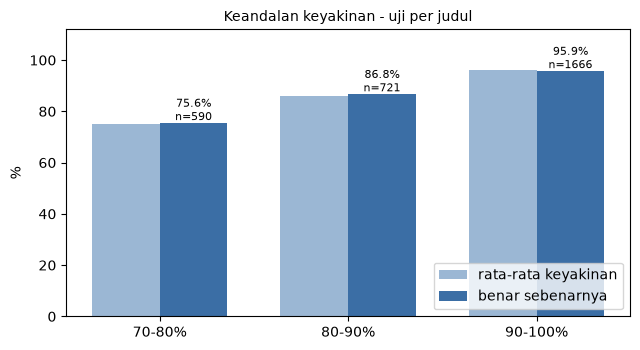

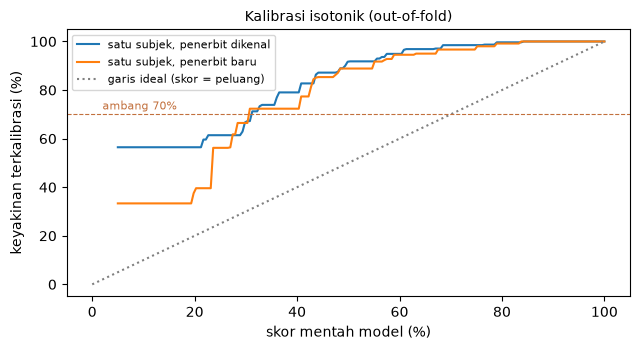

In [16]:
plot_reliability(out1, 'Keandalan keyakinan - uji per judul')
# kurva kalibrasi: skor mentah -> peluang benar (dipelajari dari data out-of-fold)
xs = np.linspace(0.05, 1, 200); fig, ax = plt.subplots(figsize=(6.5, 3.6))
for kind, nm in (('known', 'penerbit dikenal'), ('new', 'penerbit baru')):
    ax.plot(xs * 100, cal1['single'][kind].predict(xs) * 100, label=f'satu subjek, {nm}')
ax.plot([0, 100], [0, 100], ':', color='grey', label='garis ideal (skor = peluang)')
ax.axhline(70, color='#c2703d', lw=.8, ls='--'); ax.text(2, 72, 'ambang 70%', color='#c2703d', fontsize=8)
ax.set_xlabel('skor mentah model (%)'); ax.set_ylabel('keyakinan terkalibrasi (%)'); ax.legend(fontsize=8)
ax.set_title('Kalibrasi isotonik (out-of-fold)', fontsize=10); plt.tight_layout(); plt.show()

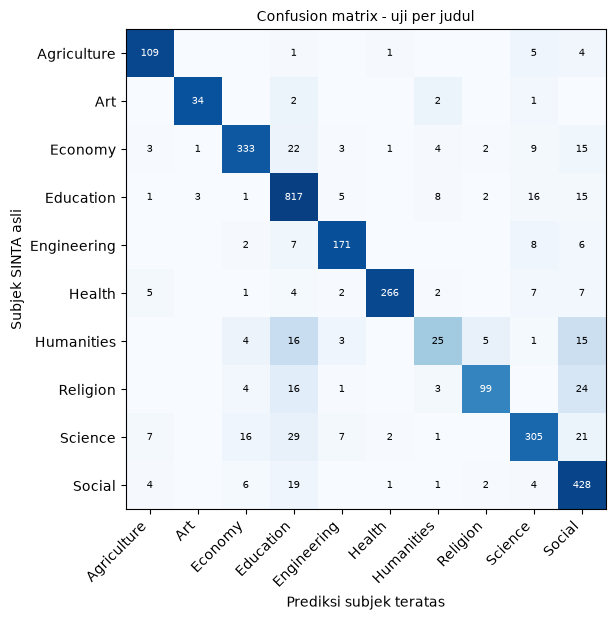

Presisi per subjek (prediksi teratas termasuk subjek SINTA):
predicted_subject_sinta  Agriculture   Art  Economy  Education  Engineering  Health  Humanities  Religion  Science  Social
n                              129.0  38.0    367.0      933.0        192.0   271.0        46.0     110.0    356.0   535.0
presisi_%                       84.5  89.5     90.7       87.6         89.1    98.2        54.3      90.0     85.7    80.0


In [17]:
parts = out1.subjek_sinta_asli.map(svc.parse_sinta_subjects)
truth = [p if p in s else s[0] for p, s in zip(out1.predicted_subject_sinta, parts)]
cm = pd.crosstab(pd.Categorical(truth, SINTA10), pd.Categorical(out1.predicted_subject_sinta, SINTA10), dropna=False)
fig, ax = plt.subplots(figsize=(7.5, 6.3))
ax.imshow(cm.values / cm.values.sum(1, keepdims=True).clip(1), cmap='Blues', vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        v = cm.values[i, j]
        if v: ax.text(j, i, v, ha='center', va='center', fontsize=7, color='white' if v / max(cm.values[i].sum(), 1) > .5 else 'black')
ax.set_xticks(range(10)); ax.set_xticklabels(SINTA10, rotation=45, ha='right'); ax.set_yticks(range(10)); ax.set_yticklabels(SINTA10)
ax.set_xlabel('Prediksi subjek teratas'); ax.set_ylabel('Subjek SINTA asli')
ax.set_title('Confusion matrix - uji per judul', fontsize=10); plt.tight_layout(); plt.show()
print('Presisi per subjek (prediksi teratas termasuk subjek SINTA):')
print((out1.assign(ok=[t in s for t, s in zip(out1.predicted_subject_sinta, parts)])
       .groupby('predicted_subject_sinta').ok.agg(['count', 'mean']).assign(mean=lambda d: (d['mean']*100).round(1))
       .rename(columns={'count': 'n', 'mean': 'presisi_%'})).T)

In [18]:
print('Contoh judul uji yang dulu Unknown pada v2.6:')
out1[out1.eks_unknown][['journal_title', 'predicted_subject_sinta_multilabel', 'subject_label_confidence', 'subjek_sinta_asli', 'benar']].head(12)

Contoh judul uji yang dulu Unknown pada v2.6:


,journal_title,predicted_subject_sinta_multilabel,subject_label_confidence,subjek_sinta_asli,benar
29,Bahastra,Education,87.18,"Humanities, Art, Education",True
41,Jurnal Ilmiah Econosains,Economy,87.18,Economy,True
47,Jurnal Enggano,Science,72.32,Education,False
51,Jurnal Konstruksia,Engineering,96.68,Engineering,True
59,DERIVATIF,Education,71.24,Science,False
72,Journal of Edugeography,Education,94.90,"Science, Education, Social",True
74,MEDISAINS,"Education, Science",78.70,Health,False
86,Jurnal Rekavasi,Engineering,95.00,"Science, Engineering",True
106,JURNAL TATSQIF,Education,96.68,Social,False
109,Jurnal Respirologi Indonesia,Health,99.65,Health,True


### 6b. Perbandingan algoritma: SVM vs Naive Bayes vs Random Forest
Untuk membuktikan bahwa Linear SVM adalah pilihan terbaik, dua algoritma lain dilatih dengan **fitur yang sama** (judul + kamus akar kata + petunjuk penerbit), **bobot multi-subjek yang sama**, dan **data latih/uji yang sama**. Pengaturan Naive Bayes (alpha = 0,05) dan Random Forest (200 pohon) sama dengan pembanding v2.6. Khusus Random Forest, dari ±78.000 fitur TF-IDF dipilih **3.000 fitur terpenting** (uji chi-square) karena Random Forest dengan seluruh fitur butuh lebih dari 1 jam per pelatihan; dengan 3.000 fitur cukup ±2 menit.

Karena satu jurnal bisa punya lebih dari satu subjek SINTA, *true label* = subjek SINTA jurnal yang cocok dengan prediksi; bila tidak ada yang cocok, subjek SINTA pertama.

In [19]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

sums_tr, n_tr = publisher_sums(tr)
Xtr_txt, _ = build_texts(tr, sums_tr, n_tr, exclude_self=True)
Xte_txt, _ = build_texts(te, sums_tr, n_tr, exclude_self=False)

def fit_pembanding(clf, langkah_tambahan=()):
    X, y, w = [], [], []
    for x, parts_ in zip(Xtr_txt, tr.parts):
        for s_ in parts_:
            X.append(x); y.append(s_); w.append(1.0 / len(parts_))
    p = make_pipeline(5)                                       # fitur & praproses sama, hanya pengklasifikasinya beda
    p.steps = p.steps[:-1] + list(langkah_tambahan) + [('clf', clf)]
    p.fit(X, np.array(y), clf__sample_weight=np.array(w)); return p

def proba10(p, X):
    P = p.predict_proba(X); cl = list(p.classes_); return P[:, [cl.index(c) for c in SINTA10]]

def nilai(P, parts_list):
    top = np.array(SINTA10)[P.argmax(1)]
    truth = [t if t in p_ else p_[0] for t, p_ in zip(top, parts_list)]
    sup = pd.Series(truth).value_counts(); ge20 = [c for c in SINTA10 if sup.get(c, 0) >= 20]
    return {'Akurasi (%)': round(accuracy_score(truth, top) * 100, 2),
            'F1 berbobot': round(f1_score(truth, top, labels=SINTA10, average='weighted', zero_division=0), 4),
            'Macro-F1 (kelas >= 20)': round(f1_score(truth, top, labels=ge20, average='macro', zero_division=0), 4)}, \
           confusion_matrix(truth, top, labels=SINTA10)

t = time.time()
model_banding = {'SVM ★ (Utama)': m1,                                    # model SVM v2.7 dari Evaluasi 1
                 'Naive Bayes': fit_pembanding(MultinomialNB(alpha=0.05)),
                 'Random Forest': fit_pembanding(RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
                                                 [('select', SelectKBest(chi2, k=3000)),   # 3.000 fitur terpenting (chi-square)
                                                  ('dense', FunctionTransformer(lambda X: X.astype(np.float32).toarray(), accept_sparse=True))])}
print(f'Naive Bayes & Random Forest dilatih dalam {time.time() - t:.0f} detik')
hasil_banding, cms = {}, {}
for nm, mdl in model_banding.items():
    hasil_banding[nm], cms[nm] = nilai(proba10(mdl, Xte_txt), te.parts.tolist())
mayor = pd.Series([1 / len(p_) for p_ in tr.parts for _ in p_], index=[s_ for p_ in tr.parts for s_ in p_]).groupby(level=0).sum().idxmax()
hasil_banding['Baseline mayoritas'] = nilai(np.eye(10)[[SINTA10.index(mayor)] * len(te)], te.parts.tolist())[0]
pd.DataFrame(hasil_banding).T

Naive Bayes & Random Forest dilatih dalam 99 detik


,Akurasi (%),F1 berbobot,Macro-F1 (kelas >= 20)
SVM ★ (Utama),86.90,0.8665,0.8251
Naive Bayes,83.94,0.8378,0.8012
Random Forest,85.72,0.8527,0.7996
Baseline mayoritas,45.11,0.2805,0.0691


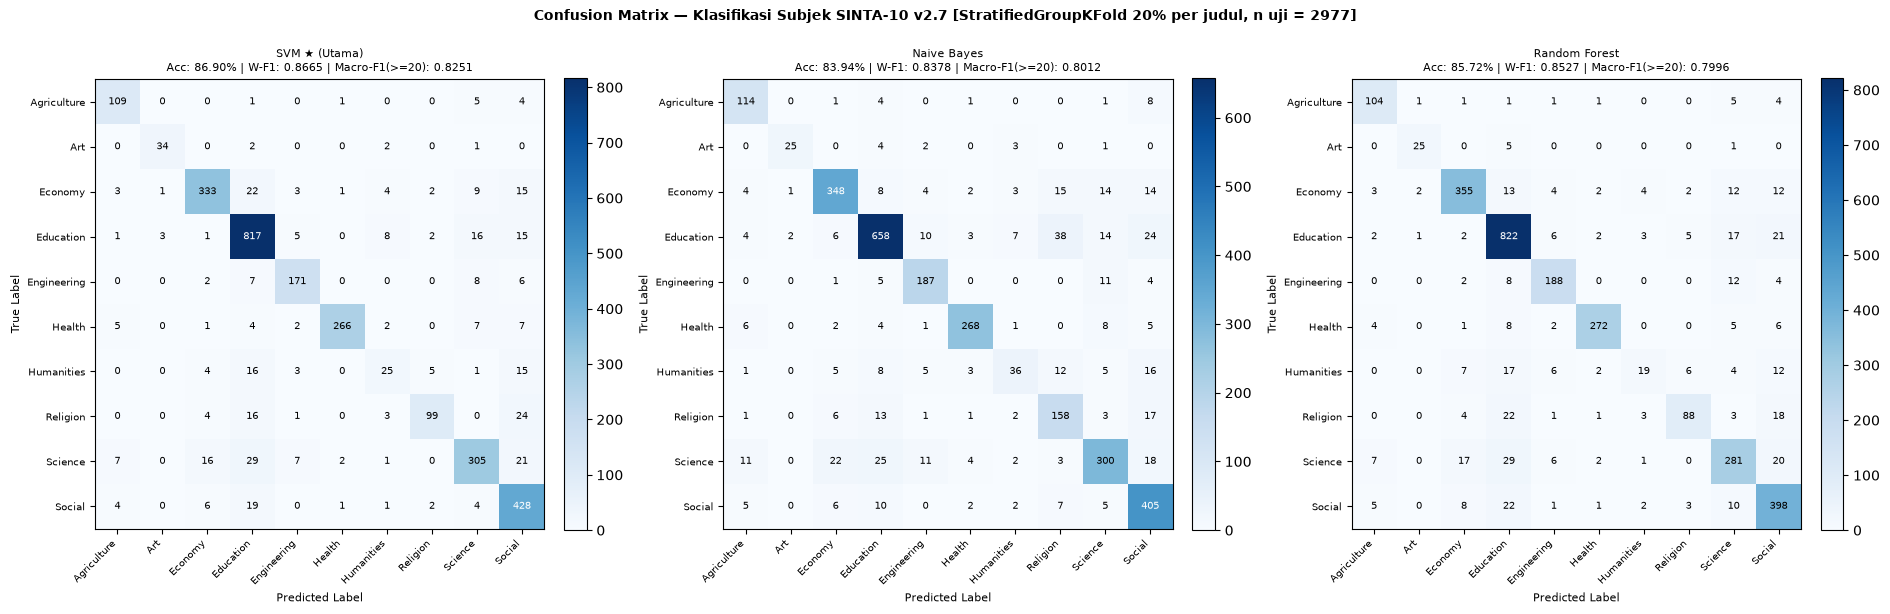

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6.2))
for ax, nm in zip(axes, cms):
    cm_ = cms[nm]; m_ = hasil_banding[nm]
    im = ax.imshow(cm_, cmap='Blues', vmin=0, vmax=cm_.max())
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm_[i, j], ha='center', va='center', fontsize=7, color='white' if cm_[i, j] > cm_.max() / 2 else 'black')
    ax.set_xticks(range(10)); ax.set_xticklabels(SINTA10, rotation=45, ha='right', fontsize=7)
    ax.set_yticks(range(10)); ax.set_yticklabels(SINTA10, fontsize=7)
    ax.set_xlabel('Predicted Label', fontsize=8); ax.set_ylabel('True Label', fontsize=8)
    ax.set_title(f"{nm}\nAcc: {m_['Akurasi (%)']:.2f}% | W-F1: {m_['F1 berbobot']:.4f} | Macro-F1(>=20): {m_['Macro-F1 (kelas >= 20)']:.4f}", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle(f'Confusion Matrix — Klasifikasi Subjek SINTA-10 v2.7 [StratifiedGroupKFold 20% per judul, n uji = {len(te)}]', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()

## 7. Evaluasi 2 — penerbit baru (simulasi jurnal dari penerbit yang belum pernah dilihat)
Pengujian paling ketat: 20% **penerbit** disisihkan seluruhnya. Model tidak pernah melihat satu pun jurnal dari penerbit-penerbit itu, sehingga kondisinya mirip jurnal baru dari penerbit baru hasil scraping.

latih 11,716 jurnal, uji 3,267 jurnal dari 1,166 penerbit yang tidak ikut dilatih


  fold 1/5 selesai (284 s)


  fold 2/5 selesai (302 s)


  fold 3/5 selesai (318 s)


  fold 4/5 selesai (336 s)


  fold 5/5 selesai (354 s)


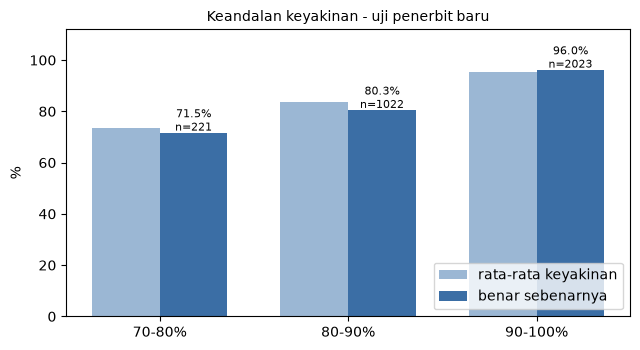

,Uji per judul,Uji penerbit baru
Ukuran,,
Jurnal uji,"2,977","3,267"
"Label ""Unknown""",0,0
Label dengan keyakinan >= 70%,100.00%,99.97%
Label yang ditampilkan benar,89.65%,89.47%
Subjek teratas termasuk subjek SINTA,86.90%,86.38%
Label satu subjek: cakupan / benar,87.0% / 90.3%,83.6% / 90.7%
Label dua subjek: cakupan / benar,13.0% / 85.2%,16.2% / 83.4%
Judul eks-Unknown v2.6: jumlah di data uji,204,212
Judul eks-Unknown v2.6: label benar,74.51%,77.83%


In [21]:
g = lab.pkey.where(lab.pkey != '', lab.tkey)
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(lab, groups=g))
tr2, te2 = lab.iloc[tr_i], lab.iloc[te_i]
print(f'latih {len(tr2):,} jurnal, uji {len(te2):,} jurnal dari {g.iloc[te_i].nunique():,} penerbit yang tidak ikut dilatih')
m2, cal2, pr2, oof2 = train_subject_model(tr2)
pred2, _, _ = load_as_service(assemble_bundle(m2, cal2, pr2, {'evaluation_split': 'eval-publisher'}), os.path.join(DIR, 'tmp_eval_pub.pkl'))
tab2, out2 = evaluate(pred2, te2)
plot_reliability(out2, 'Keandalan keyakinan - uji penerbit baru')
urutan = list(tab1.Ukuran) + [u for u in tab2.Ukuran if u not in set(tab1.Ukuran)]
ringkas = pd.DataFrame({'Uji per judul': tab1.set_index('Ukuran').Hasil, 'Uji penerbit baru': tab2.set_index('Ukuran').Hasil}).reindex(urutan).fillna('-')
ringkas

**Pembanding v2.6.** Pada pembagian data uji per judul yang sama, konfigurasi v2.6 menghasilkan subjek teratas benar **83,3%**, sedangkan judul eks-Unknown hanya **62,3%** (dan di layanan v2.6 judul tersebut diberi label *Unknown*). Rinciannya ada di `evaluation_report_v2.7.json` dan `v26_vs_v27.png`.

## 8. Pelatihan model final & penyimpanan
Setelah terbukti pada data uji, model dilatih ulang **sekali** di seluruh 14.983 jurnal berlabel, lalu disimpan sebagai satu file `.pkl` beserta sidik jari SHA-256-nya.

In [22]:
final, calib, serve_prior, oof = train_subject_model(lab)
data_sha = hashlib.sha256(open(os.path.join(DIR, 'journals_classified_v2.6.xlsx'), 'rb').read()).hexdigest()
bundle = assemble_bundle(final, calib, serve_prior, {
    'trained_on': {'source_file': 'journals_classified_v2.6.xlsx (sheet 2_Full_16768_Jurnal; asal: journals_export_20261105_161058_1.csv)',
                   'source_sha256': data_sha, 'n_journals': int(len(df)), 'n_labeled_subject': int(len(lab))},
    'oof_stats': {k: v for k, v in oof.items() if not k.startswith('_')}, 'trained_at': time.strftime('%Y-%m-%d %H:%M:%S'),
    'lexicon_groups': sorted(svc.SUBJECT_LEXICON.keys())})
MODEL_PATH = os.path.join(DIR, 'sclips_models_v2.7_notebook.pkl')
pred, sha, raw = load_as_service(bundle, MODEL_PATH)
print(f'Model disimpan: {MODEL_PATH} ({len(raw)/1e6:.1f} MB)')
print(f'SHA-256: {sha}')
print('Isi bundel:', [k for k in bundle])

  fold 1/5 selesai (418 s)


  fold 2/5 selesai (450 s)


  fold 3/5 selesai (482 s)


  fold 4/5 selesai (514 s)


  fold 5/5 selesai (547 s)


Model disimpan: sclips_train/sclips_models_v2.7_notebook.pkl (22.0 MB)
SHA-256: a002f9e19316fe7c316aa789654b2776b6510f9ccd01a70265e5085741e6f003
Isi bundel: ['model_version', 'trained_sklearn_version', 'publisher_type_pipeline', 'subject_scopus_27_pipeline', 'subject_sinta_pipeline', 'subject_calibration', 'publisher_subject_prior', 'publisher_fallback', 'verified_publisher_overrides', 'publisher_db_counts', 'optimal_thresholds', 'multidisciplinary_min_sinta_subjects', 'trained_on', 'oof_stats', 'trained_at', 'lexicon_groups']


## 9. Uji model final seperti di web
Model dimuat oleh kelas yang sama dengan server web, lalu diberi **jurnal baru** yang tidak ada di data latih, termasuk yang subjek dan penerbitnya kosong.

In [23]:
baru = [   # judul rekaan, TIDAK ada di data latih
    {'journal_id': 900001, 'journal_title': 'Tanzhim: Jurnal Manajemen Madrasah', 'publisher_name_clean': 'Sekolah Tinggi Ilmu Tarbiyah Buntet Pesantren'},
    {'journal_id': 900002, 'journal_title': 'Lex Agraria', 'publisher_name_clean': 'Universitas Sebelas Maret'},
    {'journal_id': 900003, 'journal_title': 'Respira: Jurnal Penyakit Paru', 'publisher_name_clean': ''},
    {'journal_id': 900004, 'journal_title': 'Ichthyos: Jurnal Budidaya Perairan', 'publisher_name_clean': 'Universitas Brawijaya'},
    {'journal_id': 900005, 'journal_title': 'Mediqra', 'publisher_name_clean': 'Universitas Islam Negeri Sunan Kalijaga Yogyakarta'},
    {'journal_id': 900006, 'journal_title': 'Jurnal Teknik Sipil dan Lingkungan Nusantara', 'publisher_name_clean': 'PT Ilmu Cendekia Nusantara'},
]
assert not df.journal_title.str.lower().isin([b['journal_title'].lower() for b in baru]).any()
hasil = pd.DataFrame(pred.predict_batch(baru))
hasil[['journal_title', 'predicted_subject_sinta_multilabel', 'subject_label_level', 'subject_label_confidence',
       'predicted_subject_scopus', 'predicted_subject_scopus_27', 'predicted_publisher_type', 'publisher_classification_confidence', 'processing_status', 'review_reasons']]

,journal_title,predicted_subject_sinta_multilabel,subject_label_level,subject_label_confidence,predicted_subject_scopus,predicted_subject_scopus_27,predicted_publisher_type,publisher_classification_confidence,processing_status,review_reasons
0,Tanzhim: Jurnal Manajemen Madrasah,Education,subjek,91.43,Social Sciences,Social Sciences,HEI,99.43,Classified,[]
1,Lex Agraria,Social,subjek,99.01,Social Sciences,Social Sciences,HEI,95.68,Classified,[]
2,Respira: Jurnal Penyakit Paru,Health,subjek,97.99,Health Sciences,Medicine,NaN,NaN,Classified,[]
3,Ichthyos: Jurnal Budidaya Perairan,Agriculture,subjek,91.67,Life Sciences,Agricultural and Biological Sciences,HEI,98.91,Classified,[]
4,Mediqra,"Education, Social",dua_subjek,84.12,Social Sciences,Social Sciences,HEI,98.56,Classified,[]
5,Jurnal Teknik Sipil dan Lingkungan Nusantara,Engineering,subjek,95.08,Physical Sciences,Engineering,COM,98.49,Classified,[]


In [24]:
t = time.time(); semua = predict_all(pred, df); dt = time.time() - t
print(f'Seluruh {len(semua):,} jurnal diklasifikasikan dalam {dt:.1f} detik')
print('Label "Unknown":', {k: int((semua[k] == 'Unknown').sum()) for k in ['subject_label', 'predicted_subject_sinta', 'predicted_subject_scopus', 'predicted_subject_scopus_27', 'predicted_publisher_type']})
print('Tipe penerbit kosong (jurnal tanpa nama penerbit, sengaja tidak diberi tipe):', int(semua.predicted_publisher_type.isna().sum()))
tanpa = semua[df.parts.str.len().values == 0]
print(f'Jurnal tanpa subjek SINTA: {len(tanpa):,} | keyakinan >= 70%: {(tanpa.subject_label_confidence >= 70).mean()*100:.1f}% '
      f'| rata-rata {tanpa.subject_label_confidence.mean():.1f}% | level: {tanpa.subject_label_level.value_counts().to_dict()}')
print('Status:', semua.processing_status.value_counts().to_dict())

Seluruh 16,768 jurnal diklasifikasikan dalam 11.4 detik
Label "Unknown": {'subject_label': 0, 'predicted_subject_sinta': 0, 'predicted_subject_scopus': 0, 'predicted_subject_scopus_27': 0, 'predicted_publisher_type': 0}
Tipe penerbit kosong (jurnal tanpa nama penerbit, sengaja tidak diberi tipe): 17
Jurnal tanpa subjek SINTA: 1,785 | keyakinan >= 70%: 100.0% | rata-rata 90.0% | level: {'subjek': 1545, 'dua_subjek': 240}
Status: {'Classified': 16639, 'Needs Review': 129}


In [25]:
# Pembuktian: model hasil notebook ini = model yang dirilis ke tim (sclips_models_v2.7.pkl)
rel_path = os.path.join(DIR, 'sclips_models_v2.7.pkl')
if os.path.exists(rel_path):
    rel = svc.SClipsMLPredictor(rel_path, expected_sha256=hashlib.sha256(open(rel_path, 'rb').read()).hexdigest())
    rilis = predict_all(rel, df)
    kol = ['predicted_subject_sinta', 'predicted_subject_sinta_multilabel', 'subject_label_confidence', 'predicted_subject_scopus',
           'predicted_subject_scopus_27', 'predicted_publisher_type', 'processing_status']
    a, b = semua[kol], rilis[kol]
    sama = ((a == b) | (a.isna() & b.isna())).all(axis=1)   # kosong (tanpa penerbit) dianggap sama dengan kosong
    print(f'Prediksi identik dengan model rilis: {sama.sum():,} / {len(sama):,} jurnal')
    print('(SHA-256 file berbeda hanya karena waktu pelatihan ikut tersimpan di dalam file.)')

Prediksi identik dengan model rilis: 16,768 / 16,768 jurnal
(SHA-256 file berbeda hanya karena waktu pelatihan ikut tersimpan di dalam file.)


## 10. Kesimpulan
- **Tidak ada lagi label *Unknown*.** Kamus akar kata dan petunjuk penerbit membuat judul yang tidak dikenal v2.6 tetap punya bukti untuk diklasifikasikan.
- **Keyakinan yang ditampilkan selalu ≥ 70% dan jujur.** Keyakinan dikalibrasi dari data out-of-fold. Pada data uji, label berkeyakinan sekitar 75% memang benar sekitar 75%, dan label berkeyakinan sekitar 96% benar sekitar 96%. Bila satu subjek belum cukup yakin, model menampilkan dua subjek teratas.
- **Jurnal baru tidak perlu pelatihan ulang.** Model tidak menghafal judul. Ia membaca akar kata dan pola huruf, sehingga judul baru langsung bisa diklasifikasikan. Ini dibuktikan oleh Evaluasi 2 (penerbit yang tidak pernah dilihat) dengan hasil yang setara dengan Evaluasi 1.
- **Linear SVM adalah pilihan terbaik.** Dengan fitur dan data uji yang sama, SVM mengungguli Naive Bayes dan Random Forest pada akurasi maupun F1 (bagian 6b).
- **Batasan:** Humanities masih kelas terlemah (sering tertukar dengan Education/Social). Model tipe penerbit dan Scopus-27 tidak dilatih ulang (memakai v2.6). Multidisciplinary hanya ditampilkan untuk jurnal yang subjek SINTA aslinya ≥ 4, karena kelas ini tidak bisa dipelajari dari judul.

In [26]:
print(f'Total waktu notebook: {(time.time() - T0)/60:.1f} menit')

Total waktu notebook: 10.2 menit
